# Marine gravity currents at global scale

This example adds goSPL's optional **gravity currents** (hyperpycnal flows and turbidity currents) to the global model of [`erodep_1My`](../erodep_1My): a virtual planet at 251 Ma on a 370,830-node mesh (cells of about 37 km), run for 1 Myr with marine deposition, global flexure, and here **dual lithology and stratigraphy**. It runs the model with and without the `gravity:` block and compares where the sediment goes and what the margins record.

The regional example [`Local-examples/gravity_currents`](../../Local-examples/gravity_currents) explains the module in detail. In short, a fraction of the river load reaching the sea is routed down the seafloor and deposits gradually over a run-out length:

$$\left(I - W^T \mathrm{diag}(1 - \Lambda)\right) q = s, \qquad D_i = \Lambda_i q_i, \qquad \Lambda_i = \left(1 - e^{-\ell_i / L}\right) T_d(d_i)$$

($s$ the diverted supply, $W$ the seafloor routing network, $\ell_i$ the cell size, $L$ the run-out length, $T_d$ a taper that keeps the currents from depositing on the shelf). At global scale the fraction is computed **from floods**: goSPL's discharge and load are long-term means, whose mean concentration is usually below the hyperpycnal threshold (about 40 kg/m³), but floods carry part of the load above it. With log-normal daily discharges (log-standard deviation $\sigma$) and a rating curve $Q_s \propto Q^b$, the fraction carried above the threshold has a closed form (goSPL technical guide, *Gravity currents*).

## Running the simulations

This example reuses the inputs of `erodep_1My`: run its `build_inputs.ipynb` first, so that `../erodep_1My/vars_40/` holds `mesh.npz` and `forcing251.npz`. Then

```bash
./run_all.sh            # the three runs side by side, 4 ranks each (NP=8 ./run_all.sh for more)
# or one run:
mpirun -np 4 gospl -i input-gravity.yml --summary summary_gravity.jsonl
```

Side by side with 4 ranks each on a laptop, the 20 steps take about 5 minutes per run. `input-failure.yml` adds the slope-failure trigger to `input-gravity.yml` (last section). `input-gravity.yml` differs from `input-nogravity.yml` only by:

```yaml
gravity:
    flood: {sigma: 1.2}   # fraction of each river's load carried by hyperpycnal floods
    coarse_factor: 0.3    # the coarse load is diverted with 0.3 x that fraction
    network: smoothed     # follow the clinoform network (one depression fill per step)
    runout: 1.e5          # coarse run-out length (m)
    runout_fine: 4.e5     # fine run-out length (m)
```

At this resolution the regional options (separate networks, smoothing, slope bypass) are not needed: the run-outs span several cells and the smoothed network already spreads the flow. Each step's deposit is spread over two cell sizes (about 74 km here), the default of `deposit_spread`.

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline

from scripts import gravity_global as gg

STEP = gg.last_step("sim_gravity")     # 10: 252 Ma (outputs every 100 kyr)
PATH = [(-64.0, 14.4), (-82.0, 14.4)]  # transect across one margin (lon, lat)
print("output step", STEP)

output step 10


## Gravity budget

The volume supplied to the currents falls from about $4 \times 10^5$ km³ in the first step to about $10^4$ km³ after 1 Myr, as the initial landscape adjusts and the river loads decline. With the default $\sigma = 1.2$ the floods carry about a fifth of the load reaching the sea in the first steps: on this planet the loads are large compared with the discharges, so floods often exceed the hyperpycnal threshold. Every volume supplied is deposited (the domain is closed, nothing is exported) and the budget closes to the solver tolerance.

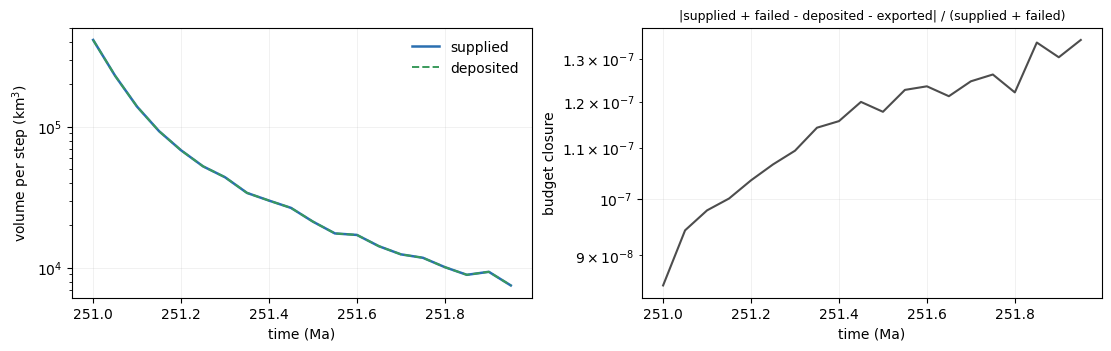

In [2]:
fig = gg.budget("summary_gravity.jsonl")
plt.show()

## Global maps

Top: the gravity deposits ring the continental margins and the epicontinental seas, thickest at the foot of the slopes. Middle: they are coarse near the coasts and in the epicontinental seas and fine on the distal margins, where only the fine fraction (with its longer run-out) arrives. Bottom: the difference in cumulative deposit between the two runs, below 200 m of water: the currents take sediment from the clinoform wedges (brown) and spread it over the slopes and the deep basins (teal). On land the two runs also differ, through the global flexure; that part is not shown.

Some basins of this virtual planet are 10 to 23 km deep. They are the terminal sinks of the seafloor network: the currents (like the clinoform cascade) fill them, and the largest gravity deposits (up to about 700 m after 1 Myr, spread over neighbouring cells) are found there.

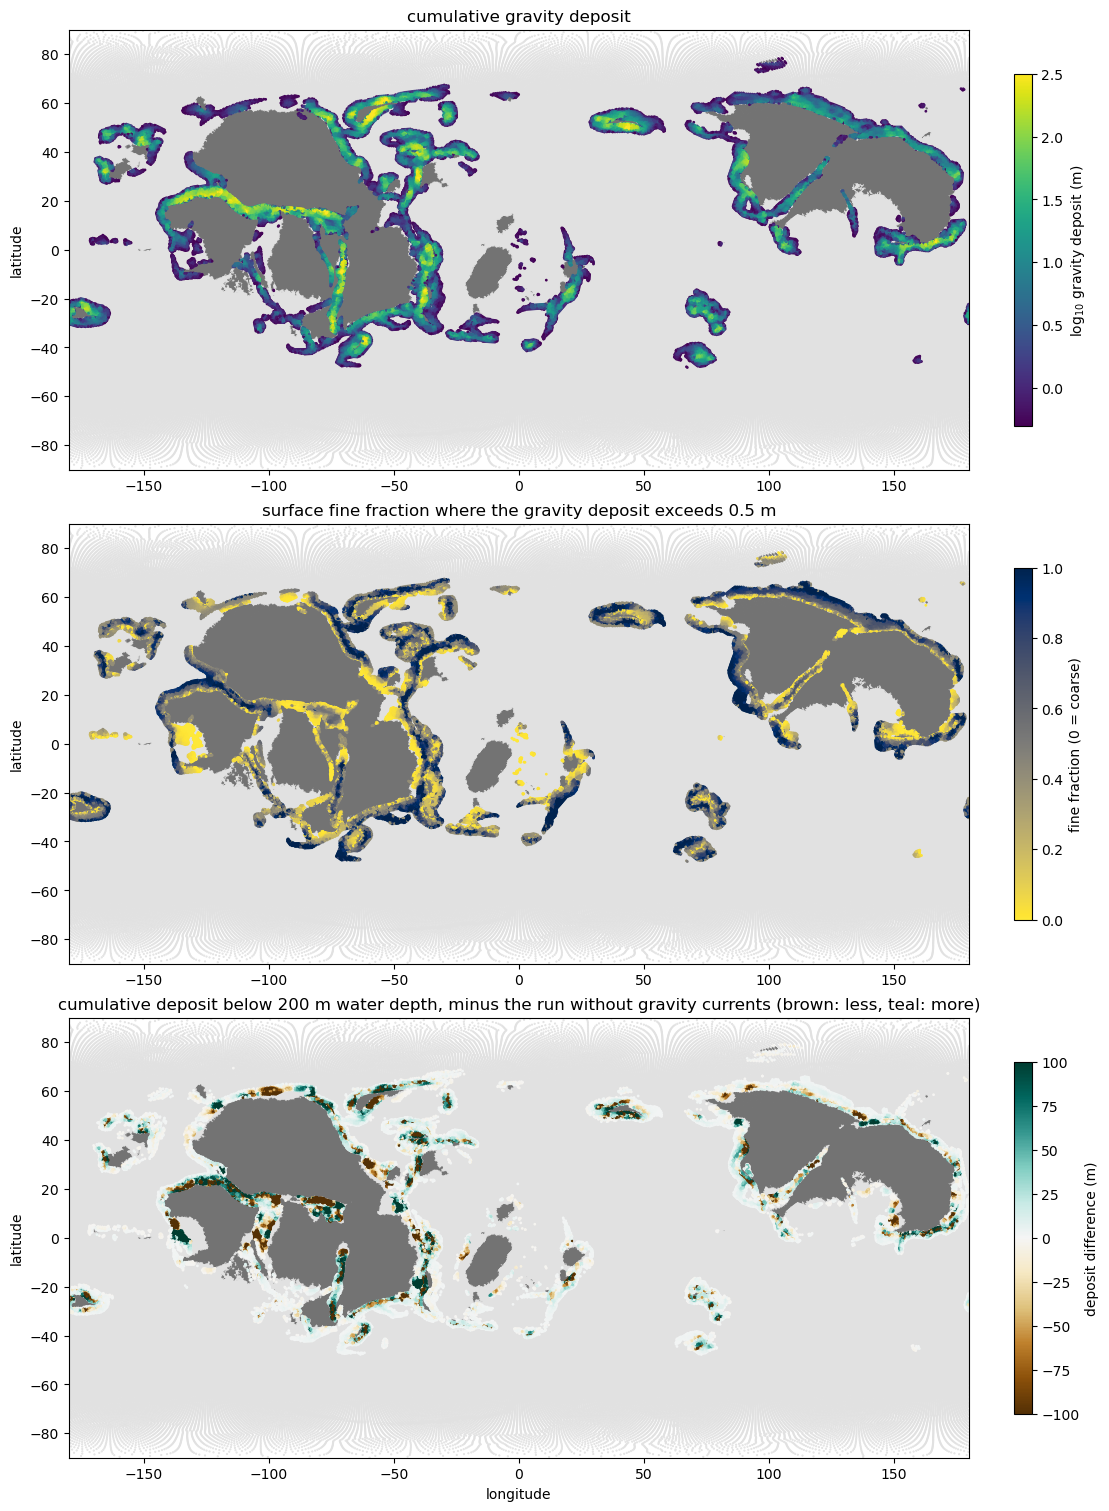

In [3]:
fig = gg.maps(STEP)
plt.show()

## One margin

A margin of the western continent (red line: the transect of the sections below). The gravity deposit is thickest at the foot of the slope, between 75°W and 80°W; the cumulative deposits of the two runs differ mostly on the slope and in the basin.

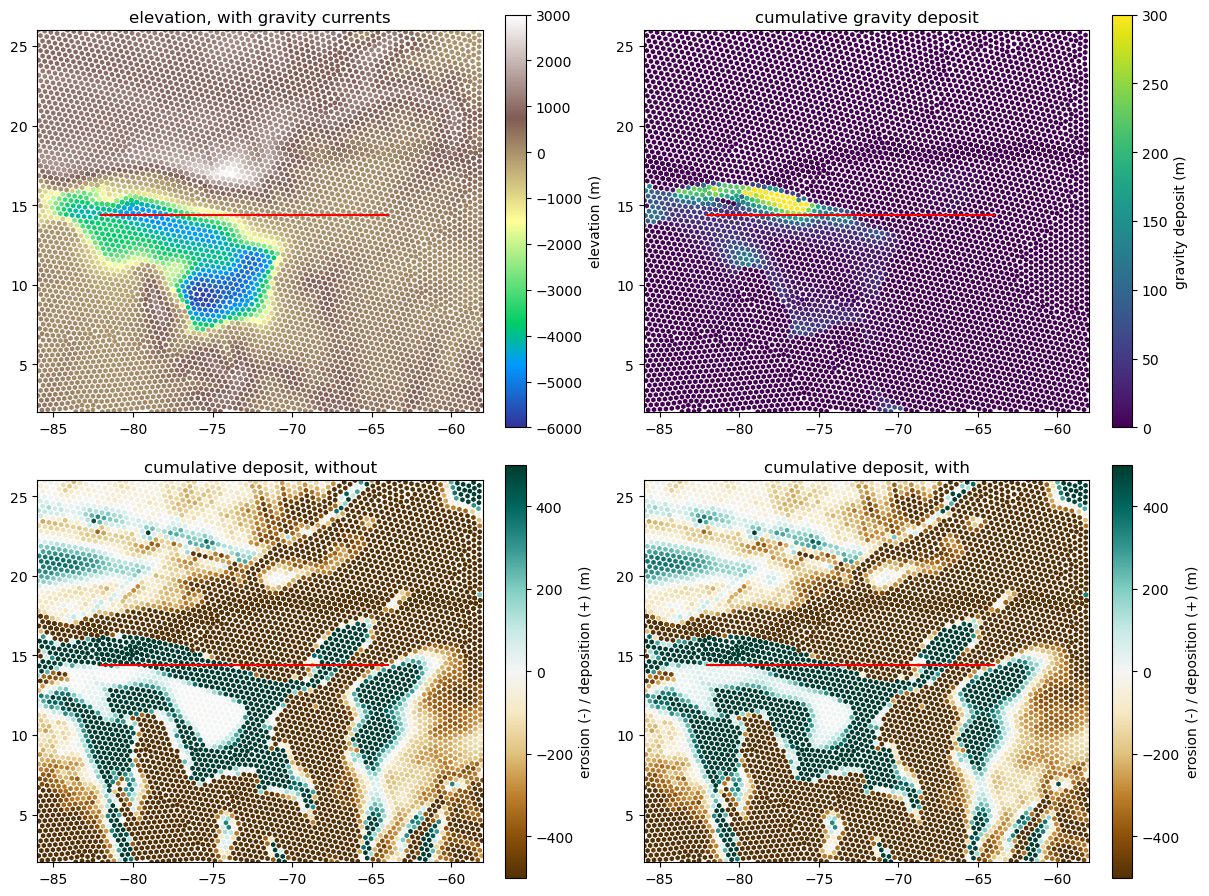

In [4]:
fig = gg.zoom(STEP, (-86, -58), (2, 26), path=PATH)
plt.show()

## Stratigraphy across the margin

Sections along the transect drawn with goSPL's `gospl.analyse.stratasection.cross_section`: filled layers between their present-day interfaces, coloured by their fine fraction (same 0 to 1 scale in both panels). Without gravity currents the clinoform cascade sorts the margin sharply: coarse layers on the upper slope (fine fraction about 0.1), fining to about 0.5 in the basin. With them, the slope and rise layers are more mixed (about 0.3 to 0.45): the currents carry mostly fine sediment past the shelf and spread it over the slope and the rise.

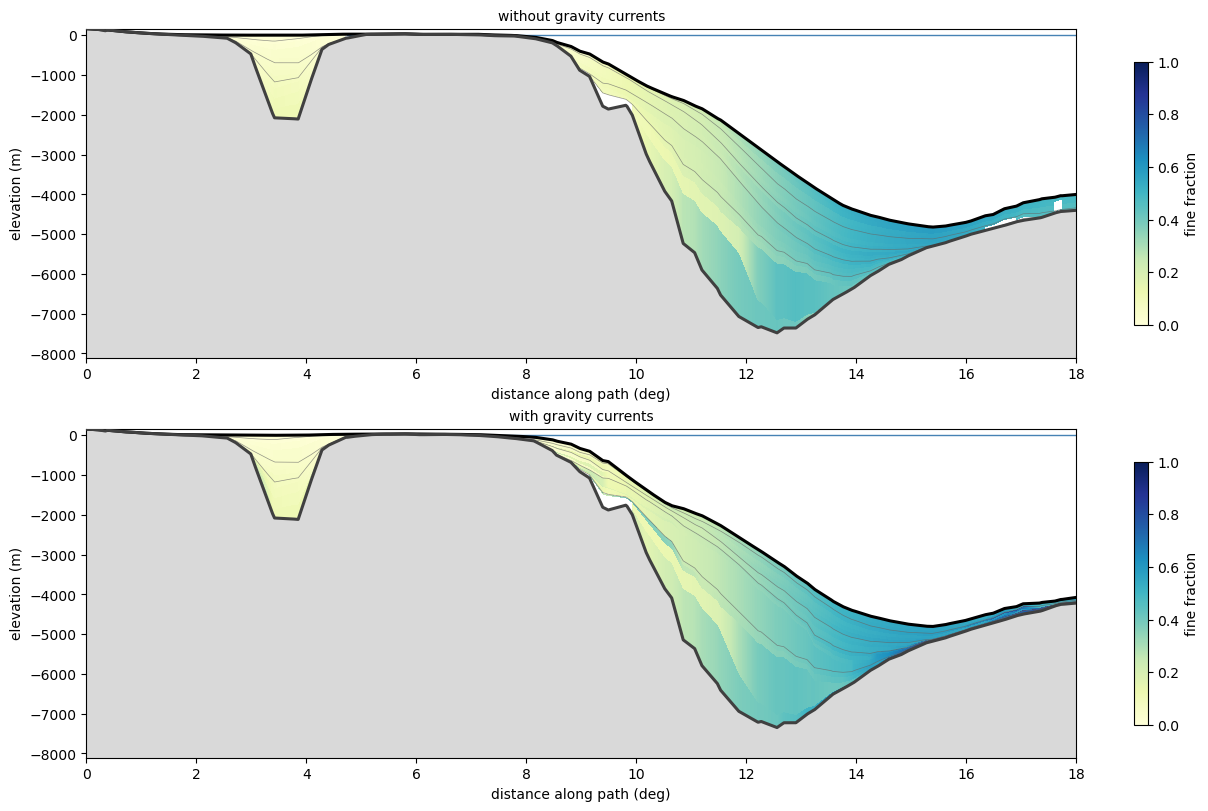

In [5]:
fig = gg.sections(STEP, PATH, color_by="lithology")
plt.show()

The same sections coloured by depositional facies, from the water depth when each layer formed. The default facies classes of `cross_section` are for a regional shelf (edges at 0, 20, 50 and 75 m); this example passes global classes instead (`GLOBAL_FACIES` in `scripts/gravity_global.py`): shelf (less than 200 m), slope (200 to 2000 m), rise (2000 to 4000 m) and abyssal plain.

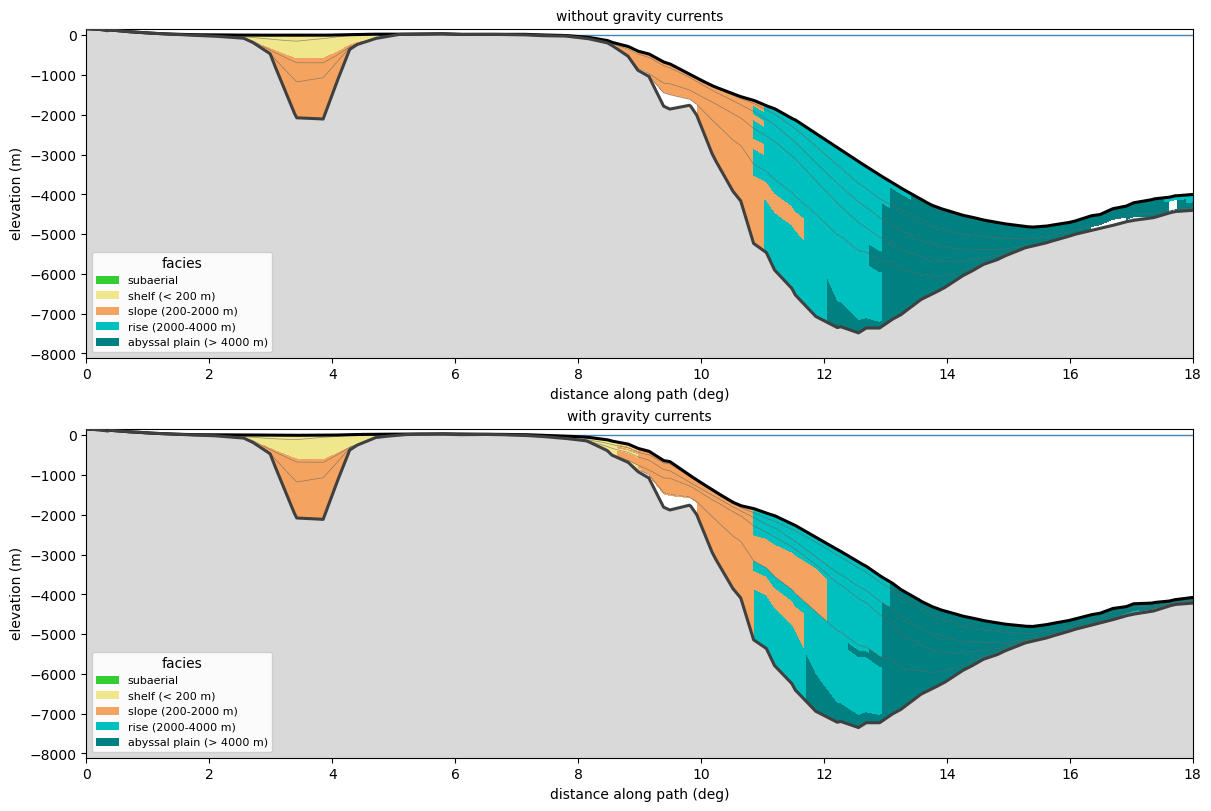

In [6]:
fig = gg.sections(STEP, PATH, color_by="facies")
plt.show()

## Slope failure

`input-failure.yml` adds goSPL's slope-failure trigger:

```yaml
    failure_slope: 0.08   # sediment deposited during the run fails where the seafloor is steeper
    max_failure: 20.      # at most 20 m per cell and 50 kyr step
```

Where the seafloor below the bypass depth is steeper than 0.08, the sediment deposited during the run fails down to that gradient (at most 20 m per step, never into the bedrock) and joins the gravity currents with its composition. On this mesh (37 km cells) the gradients are smoothed and the threshold is chosen from their distribution: 0.08 is about the steepest tenth of the sedimented seafloor of this planet, whose deep basins make its margins steeper than Earth's.

The failures start in the second step and remobilise 0.7 to 1.3 $\times 10^4$ km³ per step, by the end of the run as much as the rivers supply to the currents; the budget, with the failed volume counted with the supply, still closes to the solver tolerance.

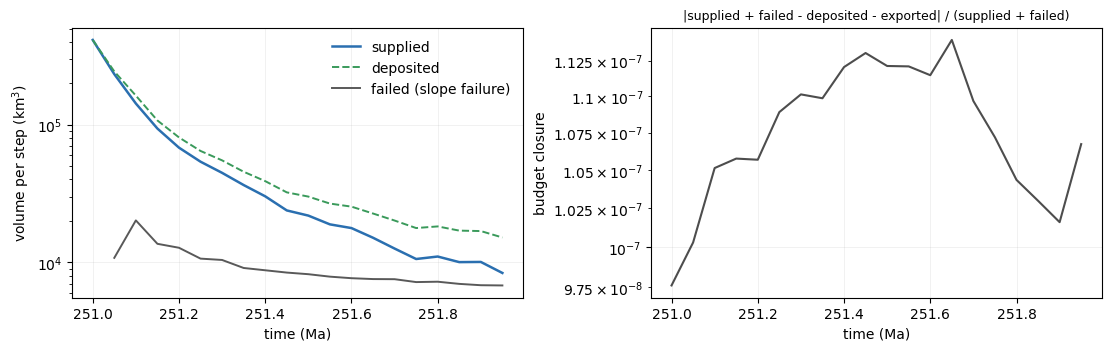

In [7]:
fig = gg.budget("summary_failure.jsonl")
plt.show()

The bottom map compares the run with slope failure to the run with gravity currents only: sediment leaves the upper margins (brown) and is deposited further down the slopes and in the basins (teal), all around the continents.

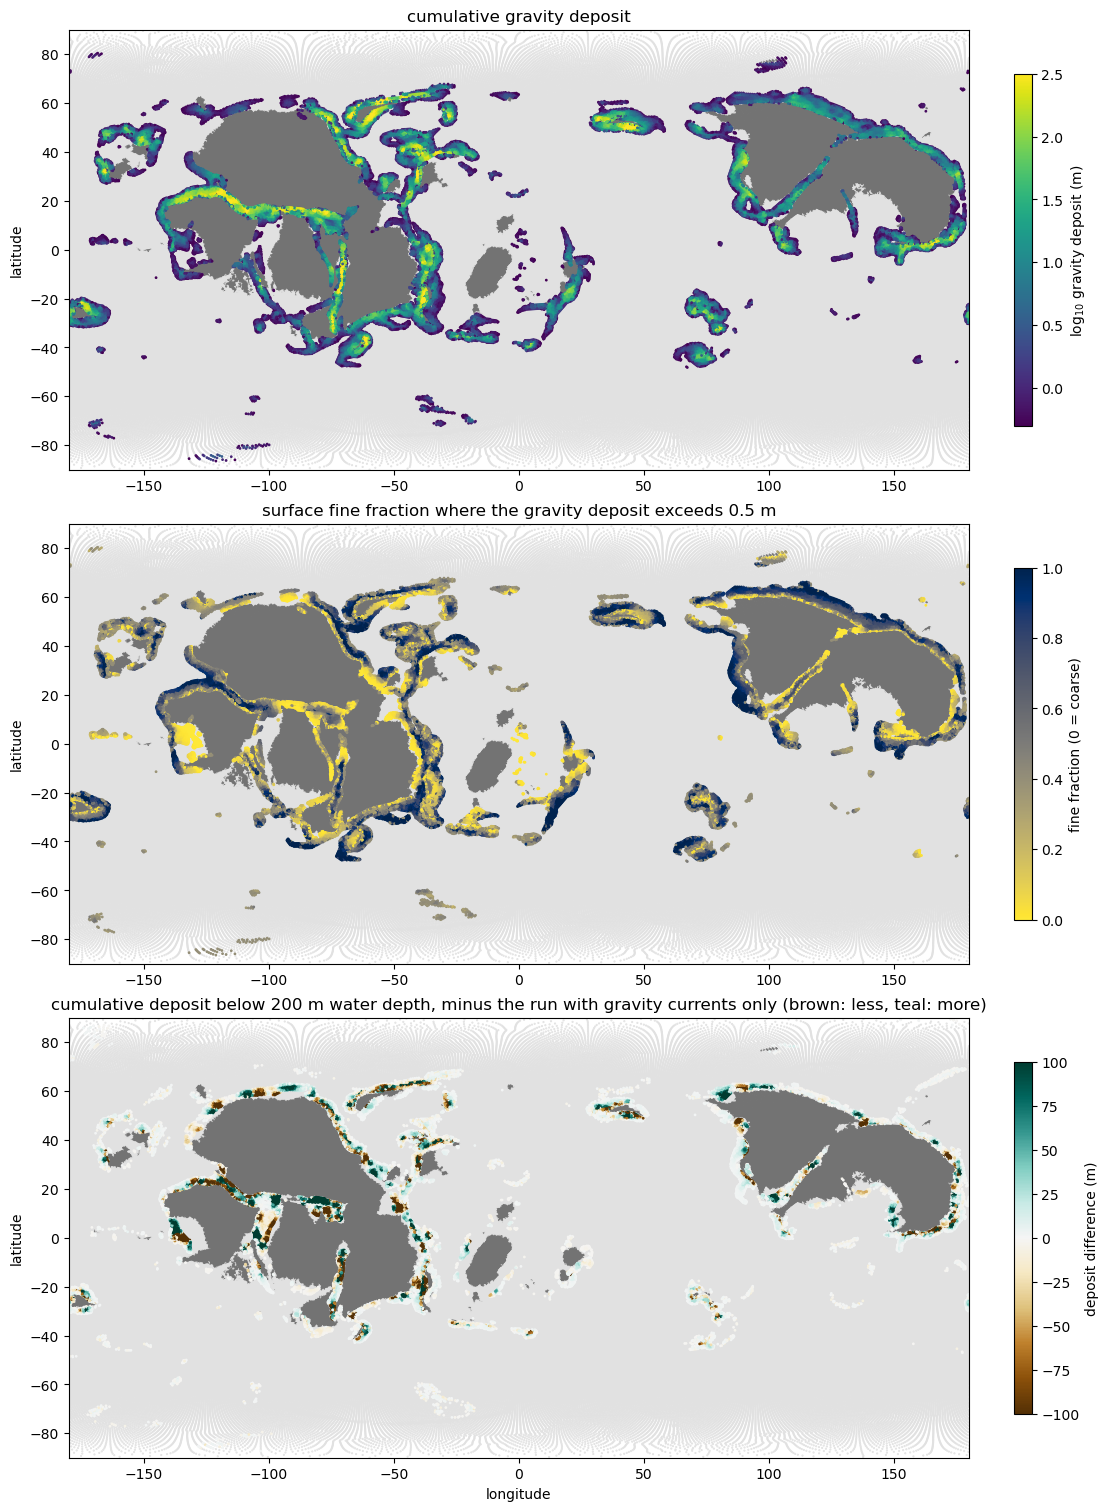

In [8]:
fig = gg.maps(STEP, sim="sim_failure", ref="sim_gravity", ref_label="with gravity currents only")
plt.show()

Across the margin of the sections above, the failures thin the upper slope deposits slightly and the material ends up in the basin fill.

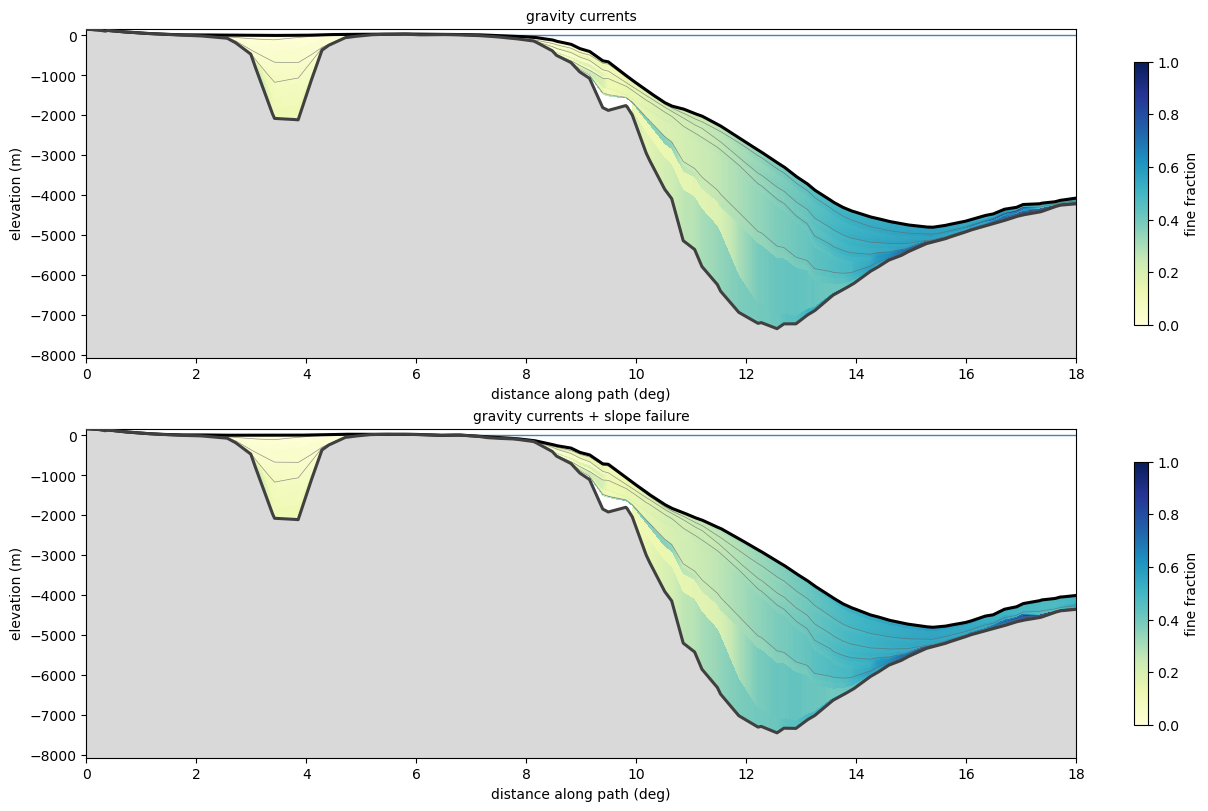

In [9]:
fig = gg.sections(STEP, PATH, color_by="lithology", runs=gg.FAILURE)
plt.show()

## Things to try

- `flood: {sigma: 2.}` for flashier rivers: the floods then carry about a third of the load.
- `fraction: 0.2` instead of the flood block: a fixed fraction everywhere, to compare with the flood-based one.
- `coarse_factor: 1.`: as much coarse as fine sediment travels with the currents.
- Change the run-outs (`runout`, `runout_fine`), keeping them several cell sizes long.
- Change `failure_slope` and `max_failure` in `input-failure.yml` (gradients depend on the mesh: read them from your own run first).

Small, steep coastal catchments, the most hyperpycnal rivers, are merged into larger outlets on a mesh this coarse, so their gravity currents are underestimated. See the goSPL user guide (*Marine gravity currents*) for the cautions.